# Bigram Language Model (makemore part 1): Revision Notebook




* Every number quoted in a markdown cell was produced by running this notebook on the real 32,033-name dataset.
* Part 9 lists what is wrong or misleading in your original notebook. Two of those are real bugs that change your results.

| # | Subsystem | One-line job | Key formula |
|---|-----------|--------------|-------------|
| 1 | Data | 32,033 names, each becomes `. name .` | $L+1$ bigrams per name of length $L$ |
| 2 | Counting (dict) | Tally every (previous, next) pair | $N(c_1,c_2)$ |
| 3 | Counting (matrix) | Same tally in a $27\times27$ grid | row = previous char, col = next char |
| 4 | Probabilities + sampling | Turn counts into probabilities, spin a roulette wheel | $P(c_2\mid c_1)=\dfrac{N(c_1,c_2)}{\sum_j N(c_1,j)}$ |
| 5 | Scoring | How surprised is the model by real names? | $\text{NLL}=-\frac1n\sum\log P$ |
| 6 | Neural-net forward | One-hot → matrix multiply → softmax | $p=\text{softmax}(xW)$ |
| 7 | Training | Nudge $W$ to reduce the NLL | $\partial L/\partial z=(p-y)/n$ |
| 8 | NN = count table | Show the trained net *is* the count table | $W\approx\log N$ (up to a row constant) |

### The whole thing in one ELI5
A kid is learning to invent names but can only remember **the last letter** they said. After "a" they have seen "n" a lot, so "n" feels likely.
**Counting** = tally marks for "which letter followed which". **Sampling** = a roulette wheel whose slices are sized by those tallies.
**Loss** = how *surprised* the kid is by real names (lower is better). The **neural net** is the same kid, but instead of tally marks they keep a table of
*scores* that you nudge by gradient descent until the surprise is as low as the tally marks achieve.

In [1]:
import math
import os
import urllib.request

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

plt.rcParams["figure.figsize"] = (6.5, 3.8)
plt.rcParams["axes.grid"] = True
print("torch", torch.__version__)

torch 2.15.0+cpu


---
## Part 1: Data

### ELI5
`names.txt` is a list of baby names, one per line. A model that only sees *one previous letter* needs to know where names **start** and **end**.
So each name gets a start marker and an end marker: `emma` → `. e m m a .` (we use `.` for both; the original's first approach used `<S>` and `<E>`).

### Math
A name with $L$ letters has $L+2$ symbols, hence $L+1$ **bigrams** (pairs of neighbours):
$$\texttt{.e},\ \texttt{em},\ \texttt{mm},\ \texttt{ma},\ \texttt{a.}\qquad(L=4\Rightarrow5\text{ bigrams})$$
Total training pairs $=\sum_{w}(\text{len}(w)+1)$.

In [2]:
URL = "https://raw.githubusercontent.com/karpathy/makemore/master/names.txt"

def load_words(path="names.txt"):
    if not os.path.exists(path):
        try:
            urllib.request.urlretrieve(URL, path)
        except Exception as err:
            raise FileNotFoundError(f"names.txt not found and download failed ({err}). Put names.txt next to this notebook.")
    return open(path, "r").read().splitlines()

words = load_words()
print(words[:10])
print("number of names:", len(words), "  shortest:", min(len(w) for w in words), "  longest:", max(len(w) for w in words))
assert len(words) == 32033

n_bigrams = sum(len(w) + 1 for w in words)
print("total bigrams  :", n_bigrams)
assert n_bigrams == 228146

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia', 'harper', 'evelyn']
number of names: 32033   shortest: 2   longest: 15
total bigrams  : 228146


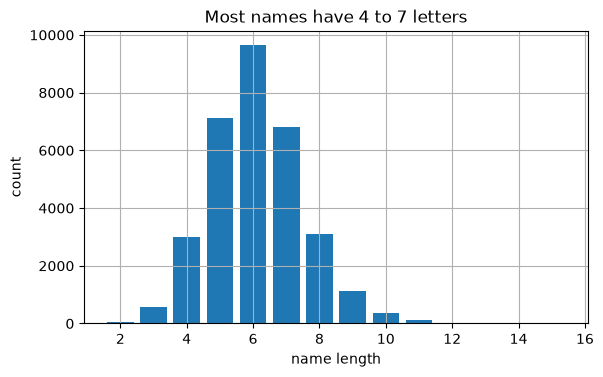

In [3]:
lengths = torch.tensor([len(w) for w in words])
plt.bar(range(2, 16), [(lengths == L).sum().item() for L in range(2, 16)])
plt.xlabel("name length"); plt.ylabel("count"); plt.title("Most names have 4 to 7 letters"); plt.show()

---
## Part 2: Counting bigrams with a dictionary

### ELI5
Walk through every name, and for every pair of neighbours make a tally mark in a notebook. The dictionary key is the pair; the value is the number of marks.

### Math
Let $N(c_1,c_2)$ be the number of times $c_2$ directly follows $c_1$ in the data. The dictionary computes exactly this table.

**Sanity check you can do by hand:** the number of bigrams starting with `<S>` and `a` equals the number of names that begin with `a`.

In [4]:
b = {}
for w in words:
    chars_ = ['<S>'] + list(w) + ['<E>']
    for c1, c2 in zip(chars_, chars_[1:]):
        b[(c1, c2)] = b.get((c1, c2), 0) + 1

top = sorted(b.items(), key=lambda kv: -kv[1])
for pair, count in top[:6]:
    print(pair, count)

assert b[('<S>', 'a')] == sum(1 for w in words if w[0] == 'a') == 4410
assert sum(b.values()) == n_bigrams
print("\nbigrams that start a name with 'a':", b[('<S>', 'a')])

('n', '<E>') 6763
('a', '<E>') 6640
('a', 'n') 5438
('<S>', 'a') 4410
('e', '<E>') 3983
('a', 'r') 3264

bigrams that start a name with 'a': 4410


**Reading it:** `('n', '<E>')` = 6763 is the most common pair: names very often **end in n**. `('<S>', 'a')` = 4410: 4,410 names **start with a**.
These counts *are* the model; everything else in this notebook is a different way of storing, using, or learning them.

---
## Part 3: Counting with a matrix (`stoi`, `itos`, `N`)

### ELI5
A dictionary of pairs is awkward for maths. Use a **27×27 grid of tally boxes** instead: **row = the letter you just saw**, **column = the letter that came next**.
26 letters + 1 special `.` = 27. We number the symbols: `.`→0, `a`→1, ..., `z`→26 (`stoi` = string-to-int, `itos` = the reverse).

### Math
$$N\in\mathbb{N}^{27\times27},\qquad N_{ij}=\#\{\text{times symbol } j \text{ follows symbol } i\}$$
* Row $0$ (`.` as *previous*) = how names **start**; it sums to the number of names.
* Column $0$ (`.` as *next*) = how names **end**; it also sums to the number of names.
* Cell $N_{00}$ (`.` followed by `.`) is always 0: no empty names. One wasted cell.
* For *every* symbol, **row sum = column sum** (each occurrence has exactly one successor and one predecessor). We use this fact in Part 4.

> **Trap: counting is not idempotent.** `N[i, j] += 1` **adds** to whatever is already there. If you re-run the counting cell without re-zeroing `N`, every count inflates.
> Your original `N[0]` sums to **38,339** instead of 32,033: it was polluted. The fix is to create `N` **in the same cell** that fills it, and assert the totals.

In [5]:
chars = sorted(list(set(''.join(words))))
stoi = {s: i + 1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [6]:
# zero-init and fill in ONE cell, so re-running is always safe
N = torch.zeros((27, 27), dtype=torch.int32)
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        N[stoi[ch1], stoi[ch2]] += 1

# invariants: if any fails, N is wrong
assert N.sum().item() == n_bigrams == 228146
assert N[0].sum().item() == len(words) == 32033          # row 0 = number of names
assert N[:, 0].sum().item() == len(words)                # col 0 = number of names
assert N[0, 0].item() == 0
assert torch.equal(N.sum(0), N.sum(1))                   # row sum == column sum for every symbol
assert N[0, 1].item() == b[('<S>', 'a')]                 # matrix agrees with the dictionary
print("N[0] (how names start):", N[0].tolist())
print("zero-count cells:", (N == 0).sum().item(), "of 729")

N[0] (how names start): [0, 4410, 1306, 1542, 1690, 1531, 417, 669, 874, 591, 2422, 2963, 1572, 2538, 1146, 394, 515, 92, 1639, 2055, 1308, 78, 376, 307, 134, 535, 929]
zero-count cells: 102 of 729


In [7]:
# the trap, reproduced: count twice without re-zeroing
N_polluted = N.clone()
for w in words[:6000]:                                    # an interrupted earlier run, say
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        N_polluted[stoi[ch1], stoi[ch2]] += 1
print("row 0 sum, clean    :", N[0].sum().item(), "  (= number of names)")
print("row 0 sum, polluted :", N_polluted[0].sum().item(), "  <- no longer equals len(words): the alarm bell")

row 0 sum, clean    : 32033   (= number of names)
row 0 sum, polluted : 38033   <- no longer equals len(words): the alarm bell


**Heatmap.** Each cell shows the pair and its count. Look for: the bright **column 0** (`x.`, names ending), the bright **row 0** (`.x`, names starting), and vowels following consonants.

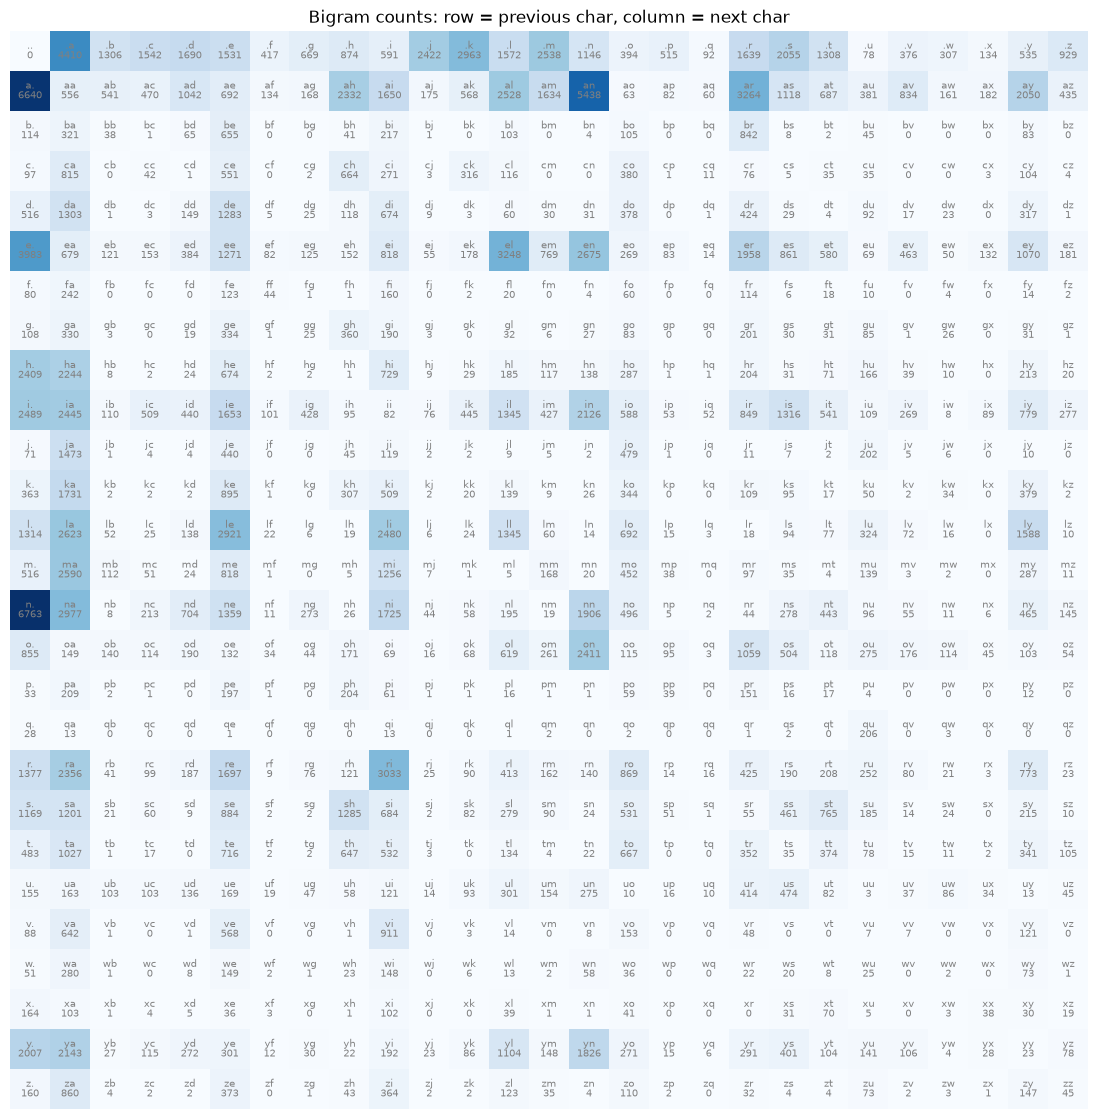

In [8]:
plt.figure(figsize=(14, 14))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray', fontsize=7)
        plt.text(j, i, N[i, j].item(), ha="center", va="top", color='gray', fontsize=7)
plt.axis('off')
plt.title("Bigram counts: row = previous char, column = next char")
plt.show()

---
## Part 4: Probabilities and sampling

### ELI5
Row `a` of the grid says how often each letter followed `a`. Divide each count by the row total and you get **probabilities that sum to 1**: the slices of a **roulette wheel**.
`torch.multinomial` spins that wheel. A `Generator` with a fixed seed makes the sequence of spins repeatable.

To invent a name: start at `.`, spin the wheel for row `.`, jump to that letter, spin *its* row, ... until you land on `.` again.

### Math
$$P(c_2\mid c_1)=\frac{N(c_1,c_2)}{\sum_{j}N(c_1,j)},\qquad \sum_{c_2}P(c_2\mid c_1)=1$$

In matrix form, divide each row of $N$ by its own row sum. That needs the row sums as a **column** `(27,1)`, not a flat vector `(27,)`.

In [9]:
# first letter of a name: row 0
p = N[0].float()
p = p / p.sum()
top5 = torch.topk(p, 5)
print("most likely first letters:", [(itos[i.item()], round(v.item(), 4)) for v, i in zip(top5.values, top5.indices)])

g = torch.Generator().manual_seed(2147483647)
ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
print("one spin of the wheel ->", itos[ix])

most likely first letters: [('a', 0.1377), ('k', 0.0925), ('m', 0.0792), ('j', 0.0756), ('s', 0.0642)]
one spin of the wheel -> c


**The roulette wheel in action.** With probabilities $p=[0.606,\ 0.303,\ 0.090]$, spin many times and compare the frequencies. 100 spins are noisy; 100,000 converge.

In [10]:
g = torch.Generator().manual_seed(2147483647)
p = torch.rand(3, generator=g)
p = p / p.sum()
print("true p          :", [round(x, 4) for x in p.tolist()])
for n_spins in (100, 100_000):
    s = torch.multinomial(p, num_samples=n_spins, replacement=True, generator=g)
    print(f"freq of {n_spins:>7} spins:", [round((s == i).float().mean().item(), 4) for i in range(3)])

true p          : [0.6064, 0.3033, 0.0903]
freq of     100 spins: [0.61, 0.33, 0.06]
freq of  100000 spins: [0.6094, 0.3013, 0.0894]


### The broadcasting bug (this one changes your results)

Your cell was `P = (N + 1).float()` then `P /= P.sum(1)`. The missing piece is **`keepdim=True`**.

PyTorch aligns shapes **from the right**:
* `P.sum(1)` has shape `(27,)`. Against a `(27, 27)` matrix it is lined up with the **last axis (columns)**, so entry $j$ divides **column $j$**, not row $j$.
* `P.sum(1, keepdim=True)` has shape `(27, 1)`. It is lined up with the **rows**. That is what we want.

Tiny example first (3×3, easy to read):

In [11]:
A = torch.tensor([[1., 2., 3.],
                  [4., 5., 6.],
                  [7., 8., 9.]])
print("A.sum(1).shape               :", A.sum(1).shape)
print("A.sum(1, keepdim=True).shape :", A.sum(1, keepdim=True).shape)

wrong = A / A.sum(1)                    # (3,3) / (3,)   -> divides COLUMNS by the row sums
right = A / A.sum(1, keepdim=True)      # (3,3) / (3,1)  -> divides ROWS by the row sums
print("\nwrong, row sums:", [round(x, 3) for x in wrong.sum(1).tolist()], " <- not 1")
print("right, row sums:", [round(x, 3) for x in right.sum(1).tolist()], " <- 1")
print("wrong[:, 0] == A[:, 0] / (sum of ROW 0):", torch.allclose(wrong[:, 0], A[:, 0] / A[0].sum()), " <- column 0 was divided by row 0's sum")

A.sum(1).shape               : torch.Size([3])
A.sum(1, keepdim=True).shape : torch.Size([3, 1])

wrong, row sums: [0.425, 1.25, 2.075]  <- not 1
right, row sums: [1.0, 1.0, 1.0]  <- 1
wrong[:, 0] == A[:, 0] / (sum of ROW 0): True  <- column 0 was divided by row 0's sum


Now the real data. Because every symbol's **row sum equals its column sum** (Part 3), the buggy version produces a matrix whose **columns** sum to 1.
Column $j$ of $N$ counts what came **before** symbol $j$, so the buggy matrix is exactly
$$P_{\text{bug}}(i,j)=\frac{N_{ij}+1}{\sum_k(N_{kj}+1)}=P(\text{previous}=i\mid\text{next}=j),$$
the **reverse** bigram model. It is a perfectly valid distribution (over the *previous* letter), so nothing crashes. But reading its rows as "what comes next" is wrong, and sampling forward from it generates the wrong names.

In [12]:
P_bug = (N + 1).float()
P_bug /= P_bug.sum(1)                          # the original: missing keepdim=True

P = (N + 1).float()
P /= P.sum(1, keepdim=True)                    # correct, with add-1 smoothing (explained in Part 5)

print("buggy  P: first 5 ROW sums:", [round(x, 3) for x in P_bug.sum(1)[:5].tolist()], " <- not probabilities")
print("buggy  P: first 3 COL sums:", [round(x, 3) for x in P_bug.sum(0)[:3].tolist()], " <- it normalised columns")
print("correct P: first 5 ROW sums:", [round(x, 3) for x in P.sum(1)[:5].tolist()])
assert torch.allclose(P.sum(1), torch.ones(27))
assert not torch.allclose(P_bug.sum(1), torch.ones(27))

buggy  P: first 5 ROW sums: [6.925, 4.367, 0.212, 0.379, 0.424]  <- not probabilities
buggy  P: first 3 COL sums: [1.0, 1.0, 1.0]  <- it normalised columns
correct P: first 5 ROW sums: [1.0, 1.0, 1.0, 1.0, 1.0]


In [13]:
def generate(prob_fn, k=5, seed=2147483647):
    """Spin the roulette wheel row by row until the end marker '.' is hit."""
    g = torch.Generator().manual_seed(seed)
    names = []
    for _ in range(k):
        out, ix = [], 0
        while True:
            ix = torch.multinomial(prob_fn(ix), num_samples=1, replacement=True, generator=g).item()
            out.append(itos[ix])
            if ix == 0:
                break
        names.append(''.join(out))
    return names

print("buggy  P (your original cell) :", generate(lambda ix: P_bug[ix]))
print("correct P                     :", generate(lambda ix: P[ix]))

buggy  P (your original cell) : ['cexze.', 'zoghkurkicqukwydwevizimittain.', 'juffk.', 'kavig.', 'jomiviubrtthrugotzi.']
correct P                     : ['cexze.', 'momasurailezitynn.', 'konimittain.', 'llayn.', 'ka.']


**Smoothing: why `N + 1`?** 102 of the 729 cells are zero: that pair never occurred, so its probability would be 0 and its log would be $-\infty$ (Part 5).
Add-1 smoothing pretends every pair was seen once:
$$P(c_2\mid c_1)=\frac{N(c_1,c_2)+1}{\sum_j N(c_1,j)+27}$$
Bigger numbers added = smoother, blurrier model. 0 = trust the data completely.

**What the samples tell you.** Names like `konimittain.` look name-ish locally but are too long and have no global structure. The model only ever sees **one previous letter**: it cannot know it has already written 9 letters. That limitation is the whole reason to move on to longer contexts later.

---
## Part 5: Scoring the model: likelihood → NLL

### ELI5
How good is the model? Ask: *how surprised is it by names that really exist?* If the model gave the true next letter probability 0.5, surprise is small ($-\ln0.5=0.69$). If it gave 0.01, surprise is large ($4.6$).
**Average surprise per letter-pair = the loss.** Lower is better.

A model that knows nothing and guesses uniformly among 27 symbols has surprise $\ln27=3.296$ everywhere. Any real model must beat that.

### Math
The probability the model assigns to the **whole** dataset is the product of every pair's probability (the **likelihood**):
$$\mathcal{L}=\prod_{i=1}^{n}P(c^{(i)}_2\mid c^{(i)}_1)$$
Products of 228,146 numbers below 1 underflow to 0, and products are awkward to differentiate. Take logs ($\log(abc)=\log a+\log b+\log c$):
$$\log\mathcal{L}=\sum_i\log P_i,\qquad \text{NLL}=-\log\mathcal{L},\qquad \text{loss}=\frac{\text{NLL}}{n}=-\frac1n\sum_i\log P_i$$

The chain of equivalences from your notebook markdown (each step has the same optimum because $\log$ is monotonic and $-1/n$ is a constant):
$$\max\ \mathcal{L}\ \Longleftrightarrow\ \max\ \log\mathcal{L}\ \Longleftrightarrow\ \min\ \text{NLL}\ \Longleftrightarrow\ \min\ \tfrac1n\text{NLL}$$

In [14]:
# full training set as index tensors: x = previous symbol, y = next symbol
xs_list, ys_list = [], []
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        xs_list.append(stoi[ch1]); ys_list.append(stoi[ch2])
xs = torch.tensor(xs_list)
ys = torch.tensor(ys_list)
num = xs.nelement()
print("examples:", num)
assert num == 228146

examples: 228146


In [15]:
# the per-pair table, for the first 3 names only (your original printed all 228,146 lines = a 4 MB output)
for w in words[:3]:
    chs = ['.'] + list(w) + ['.']
    print(f"--- {w}")
    for ch1, ch2 in zip(chs, chs[1:]):
        prob = P[stoi[ch1], stoi[ch2]]
        print(f"  {ch1}{ch2}: prob={prob:.4f}   log prob={torch.log(prob):.4f}")

--- emma
  .e: prob=0.0478   log prob=-3.0410
  em: prob=0.0377   log prob=-3.2793
  mm: prob=0.0253   log prob=-3.6753
  ma: prob=0.3885   log prob=-0.9454
  a.: prob=0.1958   log prob=-1.6305
--- olivia
  .o: prob=0.0123   log prob=-4.3965
  ol: prob=0.0779   log prob=-2.5526
  li: prob=0.1774   log prob=-1.7293
  iv: prob=0.0152   log prob=-4.1845
  vi: prob=0.3508   log prob=-1.0476
  ia: prob=0.1380   log prob=-1.9807
  a.: prob=0.1958   log prob=-1.6305
--- ava
  .a: prob=0.1376   log prob=-1.9835
  av: prob=0.0246   log prob=-3.7041
  va: prob=0.2473   log prob=-1.3971
  a.: prob=0.1958   log prob=-1.6305


In [16]:
def mean_nll(P_matrix):
    """Average negative log likelihood, vectorised and in float64 for accuracy."""
    Pd = P_matrix.double()
    return -Pd[xs, ys].log().mean().item()

print(f"uniform guessing   ln(27)        : {math.log(27):.4f}")
print(f"correct add-1 count model        : {mean_nll(P):.4f}")
print(f"buggy normalisation (your cell)  : {mean_nll(P_bug):.4f}   <- IDENTICAL loss, yet the wrong model (reverse bigram)")

P_mle = N.double(); P_mle = P_mle / P_mle.sum(1, keepdim=True)
print(f"unsmoothed counts (best possible): {mean_nll(P_mle):.4f}   <- the floor for ANY bigram model on this data")
assert mean_nll(P_mle) < mean_nll(P) < math.log(27)
assert abs(mean_nll(P_bug) - mean_nll(P)) < 1e-6          # the loss cannot tell the two apart

uniform guessing   ln(27)        : 3.2958
correct add-1 count model        : 2.4546
buggy normalisation (your cell)  : 2.4546   <- IDENTICAL loss, yet the wrong model (reverse bigram)
unsmoothed counts (best possible): 2.4540   <- the floor for ANY bigram model on this data


**Why is the buggy loss *exactly* the same?** Compare the two probabilities the loss reads for a data pair $(x,y)$, with $C=N+1$:
$$P_{\text{ok}}(y\mid x)=\frac{C_{xy}}{r_x},\qquad P_{\text{bug}}(x\mid y)=\frac{C_{xy}}{c_y},\qquad r_x=\text{row sum},\ c_y=\text{column sum}$$
so $\ \text{NLL}_{\text{bug}}-\text{NLL}_{\text{ok}}=\operatorname{mean}\log r_x-\operatorname{mean}\log c_y$.
Row sum equals column sum for every symbol ($r=c$), and the *previous* letters and *next* letters of the dataset have the same frequencies, so the two means are equal and the difference is **exactly zero**. Verify:

In [17]:
C = (N + 1).double()
r, c = C.sum(1), C.sum(0)
gap = (r[xs].log() - c[ys].log()).mean().item()
print("mean log(row sum of x) - mean log(col sum of y) =", gap)
print("measured NLL_bug - NLL_ok                        =", mean_nll(P_bug) - mean_nll(P))
assert torch.allclose(r, c) and abs(gap) < 1e-9

print("\nbuggy matrix is P(previous | next): column sums =", [round(x, 6) for x in P_bug.sum(0)[:4].tolist()])

mean log(row sum of x) - mean log(col sum of y) = 5.605958133687115e-19
measured NLL_bug - NLL_ok                        = -4.79532280550643e-09

buggy matrix is P(previous | next): column sums = [1.0, 1.0, 1.0, 1.0]


**How to read these numbers**

* $3.296\to2.454$: knowing the previous letter removes about 0.84 nats of surprise per letter.
* Unsmoothed counts give the **lowest possible** loss on the training data (it is the maximum-likelihood solution). Smoothing costs a tiny amount of training loss in exchange for never assigning probability 0.
* The buggy matrix scores **exactly** as well (see the check above). **An identical loss does not mean the same model**: it is the reverse bigram model, and the samples (Part 4) differ visibly. The loss alone cannot catch this bug.

**Danger of zero probabilities.** The original notebook's commented-out `"andrejq"` shows it. Without smoothing, one unseen pair makes the log-likelihood $-\infty$:

In [21]:
def name_nll(name, P_matrix):
    chs = ['.'] + list(name) + ['.']
    return -sum(torch.log(P_matrix[stoi[a], stoi[b]].float()) for a, b in zip(chs, chs[1:])).item() / (len(chs) - 1)

print("andrejq, unsmoothed:", name_nll("andrejq", P_mle))
print("andrejq, add-1      :", round(name_nll("andrejq", P), 4))
print("andrej  , add-1     :", round(name_nll("andrej", P), 4))

andrejq, unsmoothed: inf
andrejq, add-1      : 3.4834
andrej  , add-1     : 3.0368


**Gotcha: float32 running sums lose precision.** Your original loop did `log_likelihood += logprob` 228,146 times on a float32 tensor. Adding a small number to a big running total (about $-560{,}000$) drops low-order digits. The vectorised float64 version is both faster and exact:

In [22]:
import time
t = time.time(); ll = 0.0
for a, bb in zip(xs_list, ys_list):
    ll += torch.log(P[a, bb])                      # float32 tensor accumulating, like the original
t_loop = time.time() - t
t = time.time(); vec = mean_nll(P); t_vec = time.time() - t
print(f"sequential float32 loop : {-ll.item() / num:.6f}   ({t_loop:.2f} s)")
print(f"vectorised float64      : {vec:.6f}   ({t_vec*1000:.1f} ms)")
print("difference:", abs(-ll.item() / num - vec))

# and why we use logs at all
print("\nlikelihood as a raw product (float64):", P.double()[xs, ys].prod().item(), " <- underflows to 0")

sequential float32 loop : 2.454356   (5.22 s)
vectorised float64      : 2.454577   (5.2 ms)
difference: 0.00022056537313996927

likelihood as a raw product (float64): 0.0  <- underflows to 0


---
## Part 6: The same model as a neural network (forward pass)

### ELI5
Instead of tally marks, keep a table $W$ of **scores** (27 rows, one per previous letter; 27 columns, one per next letter). Start with random scores.
To predict after letter `e`:
1. **One-hot encode** `e`: a row of 27 numbers, all 0 except a 1 in position 5. Think of a ballot with one box ticked.
2. **Multiply by $W$.** A one-hot vector times a matrix just **picks out one row**: the scores for "what follows `e`". These scores are called **logits**.
3. **`exp`** turns any score into a positive number. We *treat the logits as log-counts*, so `exp(logits)` plays the role of the tally counts $N$.
4. **Normalise** the row to sum to 1: probabilities. Steps 3 + 4 together are called **softmax**.

So the net is the count table in disguise. Training will *discover* the counts instead of tallying them.

### Math
$$x_i=\text{onehot}(c_1^{(i)})\in\mathbb{R}^{27},\qquad z_i=x_iW\ (\text{logits}),\qquad p_{ij}=\frac{e^{z_{ij}}}{\sum_{k}e^{z_{ik}}}$$
$$\text{loss}=-\frac1n\sum_{i}\log p_{i,y_i}$$
Because $x_i$ has a single 1 at index $c_1^{(i)}$: $\ x_iW=W[c_1^{(i)},:]$ (row lookup).

inputs : [0, 5, 13, 13, 1] ['.', 'e', 'm', 'm', 'a']
targets: [5, 13, 13, 1, 0] ['e', 'm', 'm', 'a', '.']
xenc.shape: torch.Size([5, 27])  dtype: torch.float32  (float32, because it will be multiplied by float weights)


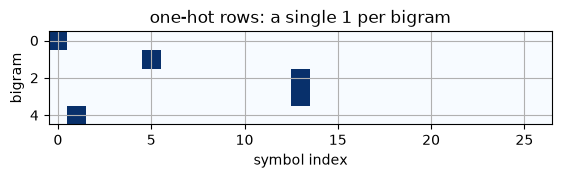

In [23]:
# toy dataset: just the first name, "emma"  ->  . e m m a .
xs_toy, ys_toy = [], []
for ch1, ch2 in zip(['.'] + list("emma"), list("emma") + ['.']):
    xs_toy.append(stoi[ch1]); ys_toy.append(stoi[ch2])
xs_toy = torch.tensor(xs_toy); ys_toy = torch.tensor(ys_toy)
print("inputs :", xs_toy.tolist(), [itos[i] for i in xs_toy.tolist()])
print("targets:", ys_toy.tolist(), [itos[i] for i in ys_toy.tolist()])

xenc = F.one_hot(xs_toy, num_classes=27).float()      # 5 x 27, one 1 per row
print("xenc.shape:", xenc.shape, " dtype:", xenc.dtype, " (float32, because it will be multiplied by float weights)")

plt.imshow(xenc, cmap="Blues"); plt.title("one-hot rows: a single 1 per bigram"); plt.xlabel("symbol index"); plt.ylabel("bigram"); plt.show()

In [24]:
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)       # 27 neurons, 27 inputs each

logits = xenc @ W                         # log-counts
counts = logits.exp()                     # like N
probs = counts / counts.sum(1, keepdims=True)    # like P  (this + the line above = softmax)

print("one-hot @ W  ==  row lookup W[xs]:", torch.allclose(xenc @ W, W[xs_toy]))
print("rows of probs sum to 1           :", torch.allclose(probs.sum(1), torch.ones(5)))
assert torch.allclose(probs, F.softmax(logits, dim=1))

one-hot @ W  ==  row lookup W[xs]: True
rows of probs sum to 1           : True


In [25]:
nlls = torch.zeros(5)
for i in range(5):
    x, y = xs_toy[i].item(), ys_toy[i].item()
    p_correct = probs[i, y]
    nlls[i] = -torch.log(p_correct)
    print(f"bigram {i+1}: {itos[x]}{itos[y]}   p(correct)={p_correct.item():.4f}   nll={nlls[i].item():.4f}")

loss = nlls.mean()
print("\nloss (average nll):", loss.item())
assert math.isclose(loss.item(), 3.7693049907684326, rel_tol=1e-6)          # matches your notebook
assert torch.allclose(loss, -probs[torch.arange(5), ys_toy].log().mean())   # the one-line "fancy indexing" form
assert torch.allclose(loss, F.cross_entropy(logits, ys_toy))                # PyTorch's built-in

bigram 1: .e   p(correct)=0.0123   nll=4.3993
bigram 2: em   p(correct)=0.0181   nll=4.0146
bigram 3: mm   p(correct)=0.0267   nll=3.6234
bigram 4: ma   p(correct)=0.0737   nll=2.6081
bigram 5: a.   p(correct)=0.0150   nll=4.2012

loss (average nll): 3.7693049907684326


**Reading this.** An untrained net gives each correct next letter a probability around 0.01 to 0.07 (uniform would be $1/27=0.037$), so the loss is about $3.77$, close to $\ln 27=3.30$ plus some random-init noise. Training must bring it down.

**One-liner to memorise:** `probs[torch.arange(n), ys]` picks, for each row $i$, the probability of the *correct* column $y_i$.
You can't write `probs[:, ys]`; that would pick the same columns for *every* row and return an $n\times n$ matrix.

**Two gotchas**

1. Your `W = torch.randn((27, 1))` demo printed `probs` all equal to `1.0`. That's correct, not interesting: with a single column, normalising each row gives 1. The weights must be `(27, 27)`.
2. The hand-rolled `exp` / normalise overflows for large logits. `F.softmax` (or `F.cross_entropy`) subtracts the row maximum first. Demo:

In [26]:
big = torch.tensor([[100.0, 101.0, 99.0]])
naive = big.exp() / big.exp().sum(1, keepdim=True)
print("naive exp (float32):", naive.tolist(), "  <- exp(100) overflows float32 -> inf/inf = nan")
print("F.softmax          :", [round(v, 4) for v in F.softmax(big, dim=1).tolist()[0]])

naive exp (float32): [[nan, nan, nan]]   <- exp(100) overflows float32 -> inf/inf = nan
F.softmax          : [0.2447, 0.6652, 0.09]


---
## Part 7: Training: gradient descent on $W$

### ELI5
Walk downhill on the loss surface. The gradient tells you which direction is *uphill*, so step the opposite way. The **learning rate** is the step size.
The 4-step recipe is the same as in micrograd: **forward → zero grad → backward → update**.

### Math
For one example with softmax probabilities $p$ and true class $y$, the gradient of the loss with respect to the **logits** is beautifully simple:
$$\frac{\partial\,\text{loss}}{\partial z_{ij}}=\frac{1}{n}\Big(p_{ij}-\mathbb{1}[j=y_i]\Big)\qquad\text{i.e. } (p-\text{onehot}(y))/n$$
Meaning: push **down** the scores of wrong letters in proportion to how much probability they got, push **up** the score of the right letter.

Since $z=XW$: $\ \dfrac{\partial\,\text{loss}}{\partial W}=X^\top\dfrac{\partial\,\text{loss}}{\partial Z}$. Because $x_i$ is one-hot, **only the rows of $W$ for letters that actually appeared as input receive gradient.**

**Regularisation** (your `+ 0.01*(W**2).mean()`): add a penalty that pulls weights to 0:
$$\text{total}=\underbrace{-\tfrac1n\textstyle\sum\log p_{i,y_i}}_{\text{data loss}}+\lambda\cdot\operatorname{mean}(W^2),\quad\lambda=0.01,\qquad \frac{\partial}{\partial W}\lambda\operatorname{mean}(W^2)=\frac{2\lambda W}{729}$$
$W\to0$ means all logits equal, hence a *uniform* distribution. So the penalty plays the same role as add-1 smoothing: it blurs the model toward uniform.

Update rule: $\ W\leftarrow W-\eta\,\dfrac{\partial\,\text{total}}{\partial W}$.

In [27]:
# Verify the gradient formula on the 5-bigram toy, WITH the regulariser, against autograd
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

xenc = F.one_hot(xs_toy, num_classes=27).float()
probs = F.softmax(xenc @ W, dim=1)
total = -probs[torch.arange(5), ys_toy].log().mean() + 0.01 * (W**2).mean()
W.grad = None                         # "set to zero" (None is the cheap way)
total.backward()

with torch.no_grad():
    dz = (probs - F.one_hot(ys_toy, 27).float()) / 5        # (p - onehot(y)) / n
    analytic = xenc.T @ dz + 2 * 0.01 * W / 729
print("analytic gradient == autograd gradient:", torch.allclose(analytic, W.grad, atol=1e-7))
print("rows of W that received gradient      :", sorted((W.grad.abs().sum(1) > 0).nonzero().flatten().tolist()))
print("input symbols in 'emma' (. e m a)     :", sorted(set(xs_toy.tolist())), " (+ regulariser touches every row, see below)")

analytic gradient == autograd gradient: True
rows of W that received gradient      : [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26]
input symbols in 'emma' (. e m a)     : [0, 1, 5, 13]  (+ regulariser touches every row, see below)


> **Note on that last line:** with the regulariser included, *every* row has a (tiny) gradient, so the check above prints all 27 rows. Without the regulariser only the rows for `.`, `e`, `m`, `a` (indices 0, 5, 13, 1) are non-zero. Try deleting the `0.01 * (W**2).mean()` term to see it.

Now the real training set (228,146 examples). We one-hot encode **once** outside the loop. Your original recomputed it every iteration.

In [28]:
xenc_all = F.one_hot(xs, num_classes=27).float()            # 228146 x 27

def full_loss(W, reg=0.01):
    logits = xenc_all @ W
    probs = F.softmax(logits, dim=1)
    data_loss = -probs[torch.arange(num), ys].log().mean()
    return data_loss + reg * (W**2).mean(), data_loss

g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

history = []                                                # (step, total loss, data loss)
for k in range(201):
    total, data_loss = full_loss(W)                         # forward
    history.append((k, total.item(), data_loss.item()))
    W.grad = None                                           # zero grad
    total.backward()                                        # backward
    if k == 0:
        print("largest |grad| entry at step 0:", W.grad.abs().max().item())
    W.data += -50 * W.grad                                  # update (lr = 50)

for k, tot, dat in history:
    if k in (0, 1, 2, 5, 10, 25, 50, 100, 150, 200):
        print(f"step {k:3d}   total={tot:.4f}   data loss={dat:.4f}")

largest |grad| entry at step 0: 0.03174407407641411
step   0   total=3.7686   data loss=3.7590
step   1   total=3.3788   data loss=3.3701
step   2   total=3.1611   data loss=3.1528
step   5   total=2.8672   data loss=2.8592
step  10   total=2.6965   data loss=2.6881
step  25   total=2.5577   data loss=2.5476
step  50   total=2.5099   data loss=2.4974
step 100   total=2.4900   data loss=2.4748
step 150   total=2.4849   data loss=2.4682
step 200   total=2.4830   data loss=2.4653


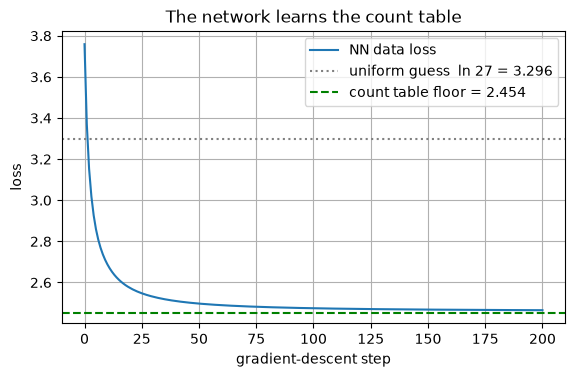

In [29]:
steps = [h[0] for h in history]
plt.plot(steps, [h[2] for h in history], label="NN data loss")
plt.axhline(math.log(27), color="gray", ls=":", label="uniform guess  ln 27 = 3.296")
plt.axhline(mean_nll(P_mle), color="green", ls="--", label=f"count table floor = {mean_nll(P_mle):.3f}")
plt.xlabel("gradient-descent step"); plt.ylabel("loss"); plt.legend()
plt.title("The network learns the count table"); plt.show()

**Reading the curve**

* Step 0 prints $3.7686$ (*total* including the penalty) and $3.7590$ (data loss only). Your original printed $3.7686$ and never trained further (Part 9, #3).
* Loss falls quickly, then flattens just **above the green line**: the count table is the best any bigram model can do, and the net can only approach it from above (the 0.01 penalty keeps it slightly away).
* **Compare like with like:** the printed `total` includes the penalty. Compare the **data loss** to the count-table numbers from Part 5.
* **Why learning rate 50 is not insane here:** the loss is a *mean* over 228,146 examples, so every gradient entry is small (see the printed maximum). With a *sum* loss, lr 50 would explode.

---
## Part 8: Sampling from the net, and the net **is** the count table

### ELI5
The net and the tally table are two different containers for the same knowledge. If we sample names from the trained net using the same random seed, we should get (nearly) the same names as from the count table. An **untrained** net should give garbage.

### Math
Training maximises likelihood. For a categorical (pick-one-of-27) model the maximum-likelihood answer is simply **relative frequencies**:
$$\hat P(j\mid i)=\frac{N_{ij}}{\sum_kN_{ik}}$$
so the net's softmax rows should converge to the (smoothed) count rows, with the logits $W_{ij}\approx\log N_{ij}+c_i$ (a constant per row cancels in softmax).

In [30]:
def nn_probs(W, ix):
    xenc_ = F.one_hot(torch.tensor([ix]), num_classes=27).float()
    return F.softmax(xenc_ @ W, dim=1).squeeze(0)

# a net trained for ONE step with lr=50 (exactly what your original notebook sampled from)
g = torch.Generator().manual_seed(2147483647)
W1 = torch.randn((27, 27), generator=g, requires_grad=True)
total, _ = full_loss(W1); W1.grad = None; total.backward(); W1.data += -50 * W1.grad

print("1-step net   :", generate(lambda ix: nn_probs(W1.detach(), ix)))
print("200-step net :", generate(lambda ix: nn_probs(W.detach(), ix)))
print("count table  :", generate(lambda ix: P[ix]))

1-step net   : ['texzmkloglquszipczktxhkmpmzistttwinmlgdukzka.', 'zr.', 'rocxtpucjwtsc.', 'gmtokmxczisqytxugkwpt.', 'dajkkluydjmscdgu.']
200-step net : ['cexze.', 'momasurailezityha.', 'konimittain.', 'llayn.', 'ka.']
count table  : ['cexze.', 'momasurailezitynn.', 'konimittain.', 'llayn.', 'ka.']


max |P_nn - P_counts| after 200 steps: 0.07702970504760742


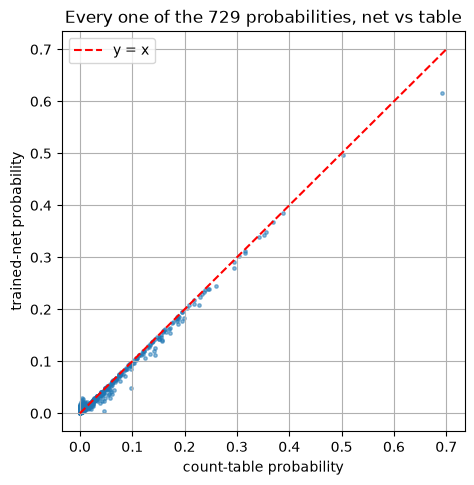

In [31]:
with torch.no_grad():
    P_nn = F.softmax(W, dim=1)
print("max |P_nn - P_counts| after 200 steps:", (P_nn - P).abs().max().item())

plt.figure(figsize=(5.2, 5.2))
plt.scatter(P.flatten(), P_nn.flatten(), s=6, alpha=0.5)
plt.plot([0, 0.7], [0, 0.7], "r--", label="y = x")
plt.xlabel("count-table probability"); plt.ylabel("trained-net probability"); plt.legend()
plt.title("Every one of the 729 probabilities, net vs table"); plt.show()

**Takeaways**

* The 1-step net's output (`texzmk...`) is essentially the random initial weights with one tiny nudge: garbage. That is where your original notebook ended.
* After 200 steps the net's names mostly match the count-table names, and the scatter hugs the diagonal: **the two models are the same function**. (Small differences remain: 200 steps is not full convergence, and the penalty term adds a mild extra smoothing.)
* So why bother with the net? The table can't scale: the count table for a context of $k$ characters needs $27^k$ rows. A neural net with shared parameters can. That is the road to MLPs and transformers.

---
## Part 9: Errors and traps 

Found by reproducing everything on the real data. Ordered by how much they change your results.

| # | Where | What the original does | Correct | Effect |
|---|-------|------------------------|---------|--------|
| 1 | `P /= P.sum(1)` | missing `keepdim=True` | `P /= P.sum(1, keepdim=True)` | **Bug.** Normalises *columns*, so `P` becomes the reverse model $P(\text{prev}\mid\text{next})$; rows sum to 6.92, 4.37, 0.21, ... (clean data). Sampling forward from it generates the wrong names. The loss is **identical** (2.454577 both ways), so the loss cannot reveal it |
| 2 | Counting cell for `N` | `N` created once, filled by a re-runnable `+=` loop | zero-init and fill in the **same cell**, assert totals | **Bug.** Your `N[0]` sums to 38,339, but must equal `len(words)` = 32,033. Every later count, probability and loss inherits the pollution (printed mean NLL 2.4560 vs true 2.4546) |
| 3 | Training | `for k in range(1)`: one step; the printed `3.7686` is the loss **before** that update | run ~100 to 200 steps (Part 7) | Final samples `texzmklog...` are from an essentially untrained net, so the notebook never shows the model working |
| 4 | Execution order | `P.shape` raises `NameError`; execution counts go 6, 3, 4, 5, 6 at the top and `65` runs **after** `64`; several cells (`stoi`, `P`, ...) have output but **no** execution count | Restart and Run All | Saved outputs may not come from the code displayed |
| 5 | Loss loop | prints 228,146 lines and accumulates in a float32 scalar | vectorised: `-P[xs, ys].log().mean()` in float64 | 4 MB of output (your file is 7.5 MB). Accumulation error about $2\times10^{-4}$ (2.45436 vs 2.45458). 1 s → 2 ms |
| 6 | Mixed tokens | dict uses `<S>`/`<E>`, matrix uses `.` for both | fine, but know it | $N_{00}$ is a dead cell; the two tables agree on every count |
| 7 | Printed loss at step 0 | $3.7686$ includes the $0.01\cdot\text{mean}(W^2)$ term | compare **data loss** ($3.7590$) to the count-table numbers | Apples-to-oranges comparison |
| 8 | `W = torch.randn((27, 1))` demo | `probs` all `1.0` | that is correct for a single column | Reads like a bug, but it is a toy; real $W$ is `(27, 27)` |
| 9 | Stale outputs | e.g. a stray `3` printed under the `multinomial` cell | re-run | Cosmetic, but a symptom of #4 |
| 10 | `torch.multinomial(p, 100)` frequencies | 0.61 / 0.33 / 0.06 vs $p=0.606/0.303/0.090$ | normal sampling noise at $n=100$ | Not a bug (Part 4 shows 100,000 spins converge) |
| 11 | No held-out data | loss measured on the same names it learned | split train/dev/test (next lectures) | With a 27×27 table overfitting is mild, but the habit matters |
| 12 | Typos in headings | `Biagram Langauge`, `stroring`, `dimenstional` | | Cosmetic |

**Habits to take away**
* After any edit: *Restart & Run All*.
* Put a cheap **invariant assert** after every counting/normalising step (`N[0].sum() == len(words)`, `P.sum(1) == 1`). #1 and #2 would both have been caught by one line each.
* `keepdim=True` whenever you reduce and then broadcast back.
* An **identical** loss is not evidence that two models are equal (bug #1). Look at samples and run invariant checks too.

---
## Part 10: One-page cheat sheet + self-test

### Formulas
| idea | formula |
|------|---------|
| bigrams per name | $L+1$ (with start/end marker) |
| conditional probability | $P(j\mid i)=\dfrac{N_{ij}}{\sum_kN_{ik}}$ |
| add-$k$ smoothing | $P(j\mid i)=\dfrac{N_{ij}+k}{\sum_kN_{ik}+27k}$ |
| likelihood | $\prod_iP_i$ |
| NLL / loss | $-\frac1n\sum_i\log P_i$ |
| uniform baseline | $\ln27=3.296$ |
| one-hot lookup | $\text{onehot}(i)\,W=W[i,:]$ |
| softmax | $p_j=\dfrac{e^{z_j}}{\sum_ke^{z_k}}$ |
| gradient wrt logits | $(p-\text{onehot}(y))/n$ |
| gradient wrt $W$ | $X^\top(p-Y)/n$ |
| L2 penalty | $\lambda\operatorname{mean}(W^2)$, grad $=2\lambda W/729$ |
| update | $W\leftarrow W-\eta\,\partial L/\partial W$ |

### Numbers worth remembering (all verified above)
32,033 names · 228,146 bigrams · 102 of 729 cells empty · uniform loss 3.296 · best bigram loss 2.454 · most common pair `n.` (6,763) · 1-step-trained net = garbage.

### Self-test (try before opening the answer)

<details><summary><b>Q1.</b> Why add 1 to every count before normalising?</summary>

102 bigrams never occur. Without it their probability is 0 and any name containing one has log-likelihood $-\infty$ (e.g. `andrejq`). Add-1 gives every pair a small positive probability.
</details>

<details><summary><b>Q2.</b> Why is <code>xenc @ W</code> just a row lookup?</summary>

$x$ is one-hot, so the sum $\sum_ix_iW_{i,:}$ has exactly one non-zero term: the row of $W$ at the index of the 1. That row is the logits for "what comes after this letter".
</details>

<details><summary><b>Q3.</b> What does <code>P /= P.sum(1)</code> do wrong, and why doesn't it crash?</summary>

`P.sum(1)` has shape `(27,)`, which PyTorch aligns with the *last* axis, so it divides **column** $j$ by the sum of **row** $j$. Shapes are broadcast-compatible, so there's no error. Since row sum = column sum for this data, the result's *columns* sum to 1: it is the reverse model $P(\text{prev}\mid\text{next})$, and it even has the same loss. Fix: `keepdim=True`.
</details>

<details><summary><b>Q4.</b> Why use the <i>log</i> of the likelihood?</summary>

A product of 228,146 probabilities underflows to 0 and is hard to differentiate; the log turns it into a sum of well-scaled numbers. Maximising the log gives the same optimum because log is monotonic.
</details>

<details><summary><b>Q5.</b> What loss does a model that guesses uniformly over 27 symbols get?</summary>

$\ln27\approx3.296$. A trained bigram model gets about $2.454$.
</details>

<details><summary><b>Q6.</b> The sampled names at the end of your notebook looked like random letters. Why?</summary>

Training ran for one step (`range(1)`), so the weights were almost still the random initialisation. After 100 to 200 steps the samples resemble the count-table names.
</details>

<details><summary><b>Q7.</b> If $p=[0.7,\,0.2,\,0.1]$ and the true class is index 1, what is the gradient with respect to the logits (for $n=1$)?</summary>

$p-\text{onehot}(y)=[0.7,\ 0.2-1,\ 0.1]=[0.7,\,-0.8,\,0.1]$. Gradient descent lowers logits 0 and 2 and raises logit 1.
</details>

<details><summary><b>Q8.</b> Why can the trained net never beat the unsmoothed count table on the training data?</summary>

Relative frequencies are the exact maximum-likelihood solution for a table of categorical distributions; the net represents the same family of distributions, so it can at best match them (and the regulariser keeps it slightly above).
</details>

In [32]:
# Final regression checks: every claim made in the markdown that is a number
assert N.sum().item() == 228146 and N[0].sum().item() == 32033
assert (N == 0).sum().item() == 102
assert math.isclose(mean_nll(P_mle), 2.4540, abs_tol=5e-4)
assert math.isclose(mean_nll(P), 2.4546, abs_tol=5e-4)
assert math.isclose(history[0][1], 3.7686, abs_tol=5e-4) and math.isclose(history[0][2], 3.7590, abs_tol=5e-4)
assert history[-1][2] < 2.47 and history[-1][2] > mean_nll(P_mle)
print("all numbers quoted in the notes reproduce")

all numbers quoted in the notes reproduce
